# Predicting thalamic activity from scalp EEG
**Mock project, OpenNeuro ds007216 (simultaneous EEG-fMRI, 24 subjects × 2 sessions)**

Can classical ML on scalp-EEG features tell, window by window, how active the thalamus is (as measured by simultaneous fMRI)?
The aim is to show a careful, leakage-free pipeline and an honest reading of the result, not a scientific claim.

This notebook runs top to bottom from the cached outputs of `scripts/01-05` (see `README.md`).
If `outputs/results` is missing, it fits the models itself with a small null (`N_NULL_NOTEBOOK`).

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display
from thalamic import config, features, model, plots

paths = config.get_paths()
N_NULL_NOTEBOOK = 20
runs = pd.read_csv(paths.derived / "runs.csv", dtype=str)
print("data:", paths.data, "| outputs:", paths.outputs)

data: C:\Users\galle\VSProjects\EEG_fMRI_thalamic\data | outputs: C:\Users\galle\VSProjects\EEG_fMRI_thalamic\outputs


## 1. Pipeline

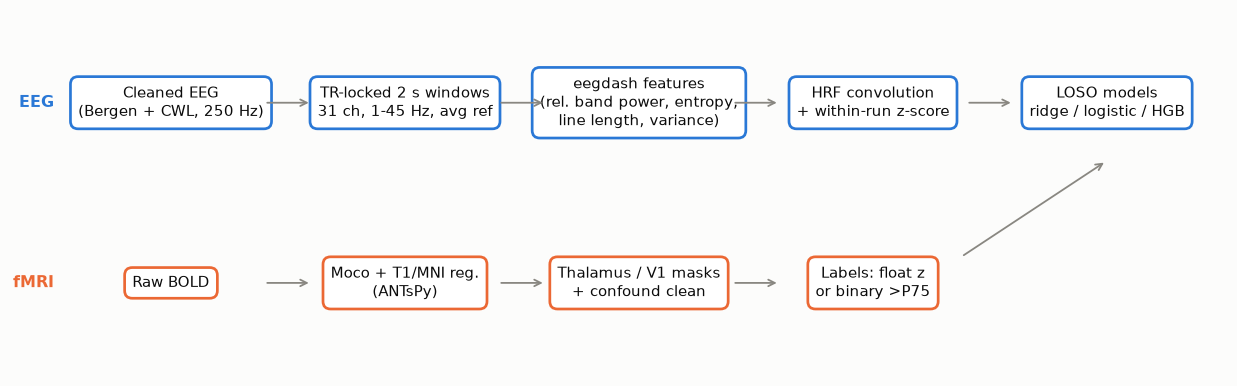

In [2]:
plots.plot_pipeline(paths.figures / "pipeline.png")
display(Image(filename=str(paths.figures / "pipeline.png")))

## 2. Data and quality control
**EEG.** We use the dataset's cleaned derivatives (`*_eeg_Bergen_CWreg.set`): gradient and BCG artifacts were removed upstream (Bergen toolbox) and CWL regression was applied.
The recordings are found through **eegdash** (`EEGDash().find`). We band-pass 1-45 Hz with no notch: line noise is at 60 Hz, which the 45 Hz low-pass already removes. Then we cut one 2-s window per scanner volume marker and extract features with the **eegdash** feature bank.

The PSD below marks the slice-excitation harmonics (13.5 Hz and multiples). Any residual gradient energy would show up there, inside the alpha/beta bands.

2 EEG PSD QC images


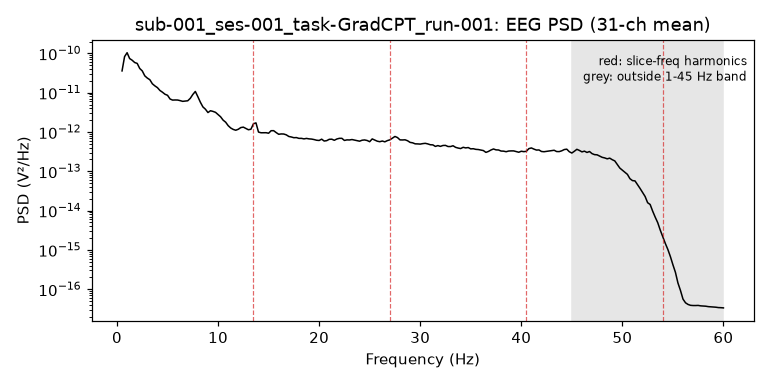

In [3]:
psd = sorted(paths.qc.glob("sub-*/ses-*/*_desc-eegpsd.png"))
print(len(psd), "EEG PSD QC images")
display(Image(filename=str(psd[0])))

**fMRI masks.** The thalamus (L/R), V1 control and WM/CSF confound masks are warped MNI → session-1 T1 → mean EPI.
Check that the thalamus sits medial to the internal capsule and V1 along the calcarine sulcus. All runs are listed in `outputs/qc/index.html`.

,stem,n_vols,n_thal_vox,n_thal_expected,coverage,fd_mean
0,sub-001_ses-001_task-GradCPT_run-001,240,1090,2574.5,1.0,0.102
1,sub-002_ses-001_task-GradCPT_run-001,240,1297,2574.5,1.0,0.061


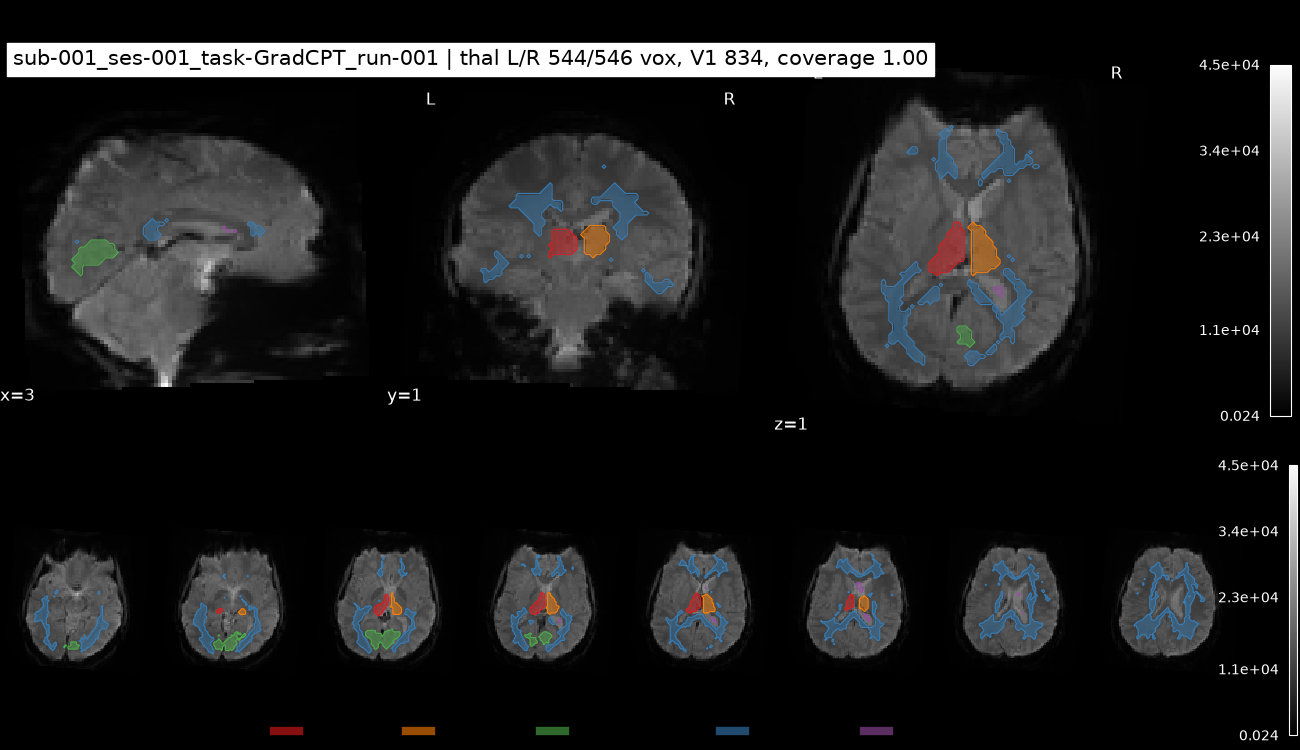

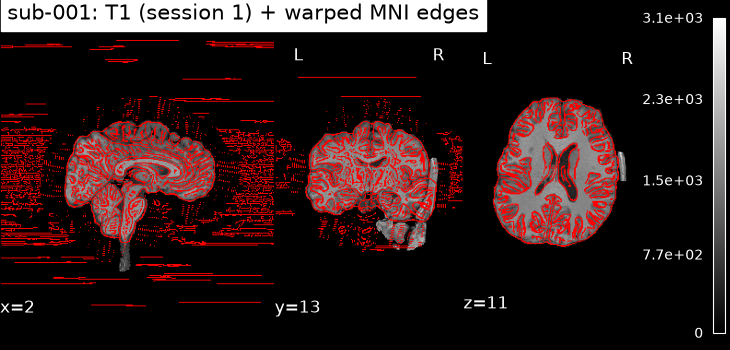

In [4]:
qc = pd.DataFrame([json.loads(p.read_text()) for p in sorted((paths.roi / "qc_summary").glob("*.json"))])
display(qc[["stem", "n_vols", "n_thal_vox", "n_thal_expected", "coverage", "fd_mean"]].round(3))
masks = sorted(paths.qc.glob("sub-*/ses-*/*_desc-masks.png"))
display(Image(filename=str(masks[0])))
anat = sorted(paths.qc.glob("sub-*/sub-*_mni_to_t1.png"))
if anat: display(Image(filename=str(anat[0]), width=650))

## 3. The modeling table
EEG features are **convolved forward with the canonical HRF** instead of shifting the BOLD backwards. Each feature is z-scored within its run, and scrubbed TRs (FD > 0.5 mm or CWL outliers) and the 16-s warm-up are dropped.

Every window carries **two label options**:
* **float**: `thal_z`, the cleaned thalamic BOLD z-scored within subject;
* **binary**: `thal_active`, 1 if `thal_z` is above the subject's 75th percentile, else 0.

In [5]:
table = pd.read_parquet(paths.table)
feat_cols = features.feature_columns(table)
print(f"{len(table)} windows, {len(feat_cols)} features, {table.subject.nunique()} subjects, {table.stem.nunique()} runs")
display(table.groupby("subject").agg(windows=("tr", "size"), runs=("stem", "nunique"),
                                     active_rate=("thal_active", "mean")).round(3).T)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(table.thal_z, bins=50, color=plots.BLUE); ax[0].set(title="float label: thal_z", xlabel="z")
table.thal_active.value_counts().sort_index().plot.bar(ax=ax[1], color=[plots.MUTED, plots.ORANGE])
ax[1].set(title="binary label: thal_active", xticklabels=["inactive", "active"]); plt.show()

438 windows, 248 features, 2 subjects, 2 runs


subject,001,002
windows,216.00,222.000
runs,1.00,1.000
active_rate,0.25,0.252


C:\Users\galle\AppData\Local\Temp\ipykernel_6672\2659371610.py:9: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ax[1].set(title="binary label: thal_active", xticklabels=["inactive", "active"]); plt.show()


## 4. Leave-one-subject-out models
* `float` → ridge regression (scored by Pearson r per held-out subject); `binary` → logistic regression (ROC-AUC; class-balanced, because positives are 25%).
* Comparison: histogram gradient boosting.
* Null: circular shifts of the target within each run (keeps its autocorrelation).
* Controls: V1 as target; thalamus with V1 regressed out; thalamus without alpha features; per task.

In [6]:
if (paths.results / "results.json").exists():
    results = model.load_results(paths.results)
else:
    results = {m: model.run_mode(table, feat_cols, m, N_NULL_NOTEBOOK, n_jobs=-1) for m in ("float", "binary")}
    model.save_results(results, paths.results)
for mode, r in results.items():
    display(Markdown(f"### {mode} labels ({model.METRIC[mode]}, chance = {model.CHANCE[mode]})"))
    display(pd.DataFrame(r["summary"]).T.round(4))

### float labels (Pearson r, chance = 0.0)

,metric,chance,mean,sem,n_subjects,n_above_chance,wilcoxon_p,null_mean,null_95,perm_p
thalamus (linear),Pearson r,0.0,-0.099771,0.009434,2,0,1.0,-0.016654,0.097391,0.904762
"thalamus (linear), GradCPT only",Pearson r,0.0,-0.099771,0.009434,2,0,1.0,NaN,NaN,NaN
thalamus (HGB),Pearson r,0.0,-0.138731,0.085524,2,0,1.0,NaN,NaN,NaN
V1 control,Pearson r,0.0,0.105069,0.156634,2,1,0.5,NaN,NaN,NaN
thalamus minus V1,Pearson r,0.0,-0.086162,0.007999,2,0,1.0,NaN,NaN,NaN
"thalamus, no alpha",Pearson r,0.0,-0.104988,0.001159,2,0,1.0,NaN,NaN,NaN


### binary labels (AUC, chance = 0.5)

,metric,chance,mean,sem,n_subjects,n_above_chance,wilcoxon_p,null_mean,null_95,perm_p
thalamus (linear),AUC,0.5,0.432953,0.038698,2,0,1.0,0.490675,0.543199,0.904762
"thalamus (linear), GradCPT only",AUC,0.5,0.432953,0.038698,2,0,1.0,NaN,NaN,NaN
thalamus (HGB),AUC,0.5,0.415784,0.043635,2,0,1.0,NaN,NaN,NaN
V1 control,AUC,0.5,0.649731,0.007756,2,2,0.25,NaN,NaN,NaN
thalamus minus V1,AUC,0.5,0.459564,0.004314,2,0,1.0,NaN,NaN,NaN
"thalamus, no alpha",AUC,0.5,0.429981,0.037554,2,0,1.0,NaN,NaN,NaN


C:\Users\galle\VSProjects\EEG_fMRI_thalamic\src\thalamic\plots.py:168: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage("standard_1020")


C:\Users\galle\VSProjects\EEG_fMRI_thalamic\src\thalamic\plots.py:168: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  info.set_montage("standard_1020")


### Figures, float labels

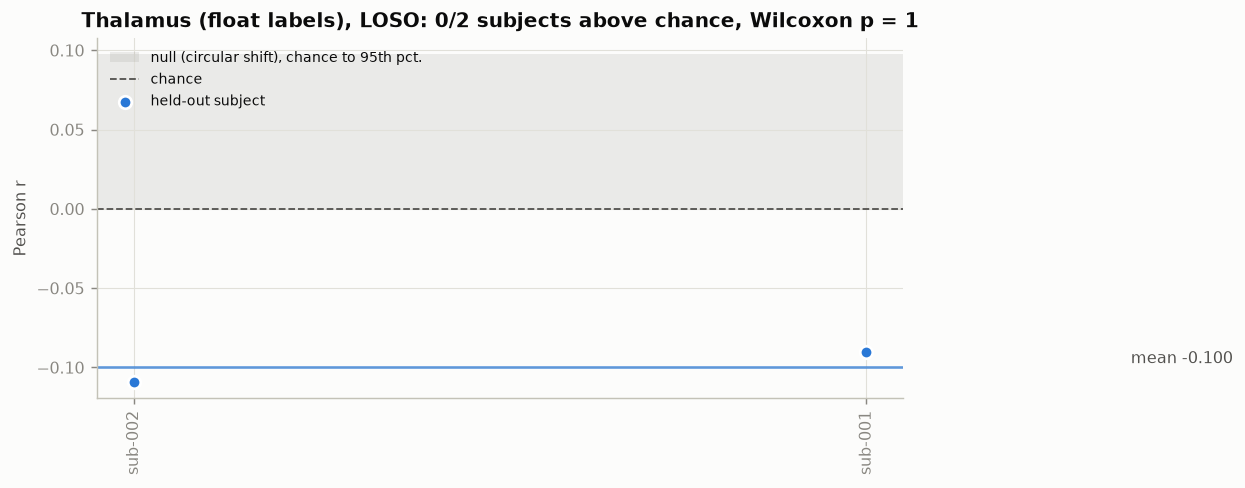

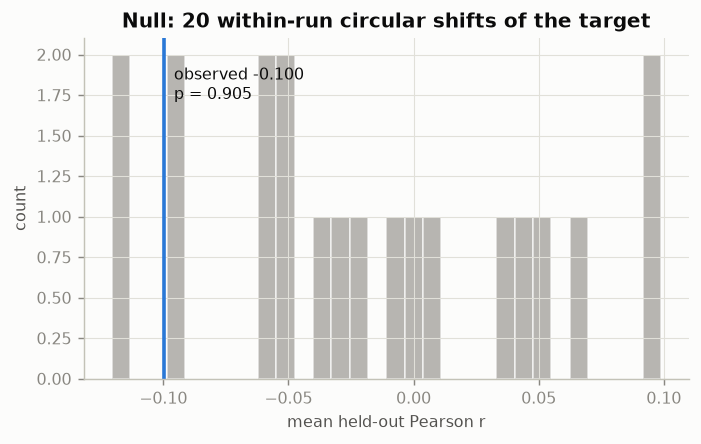

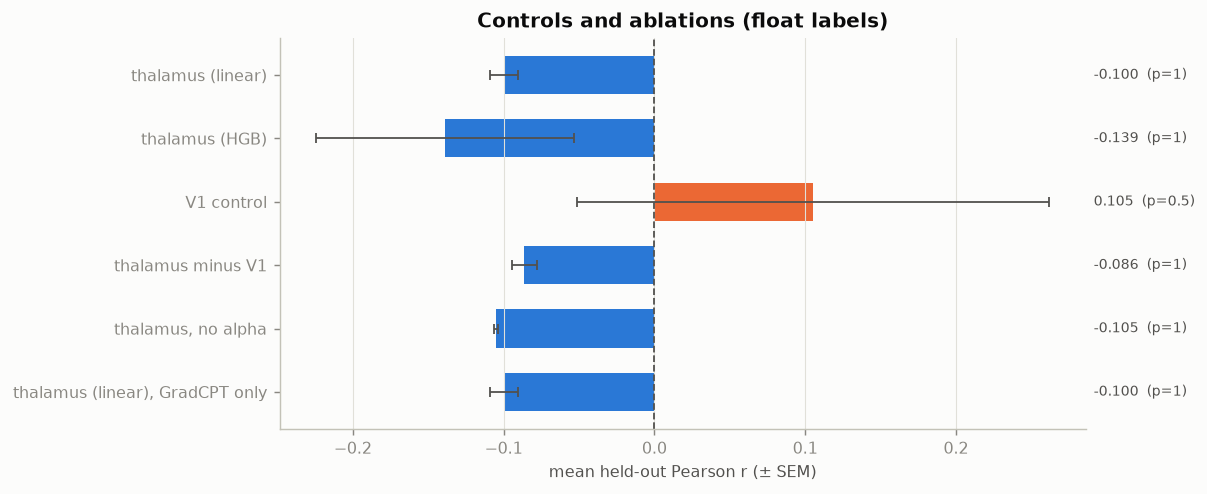

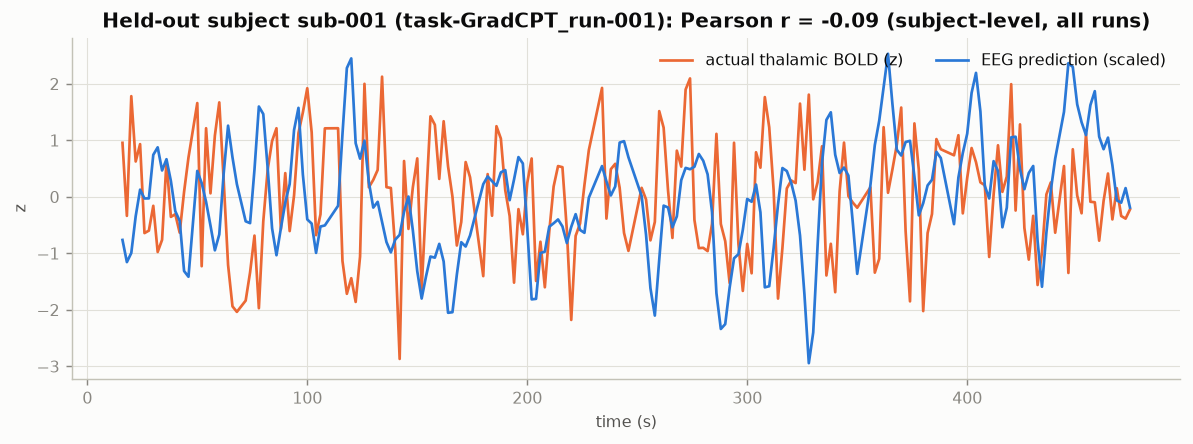

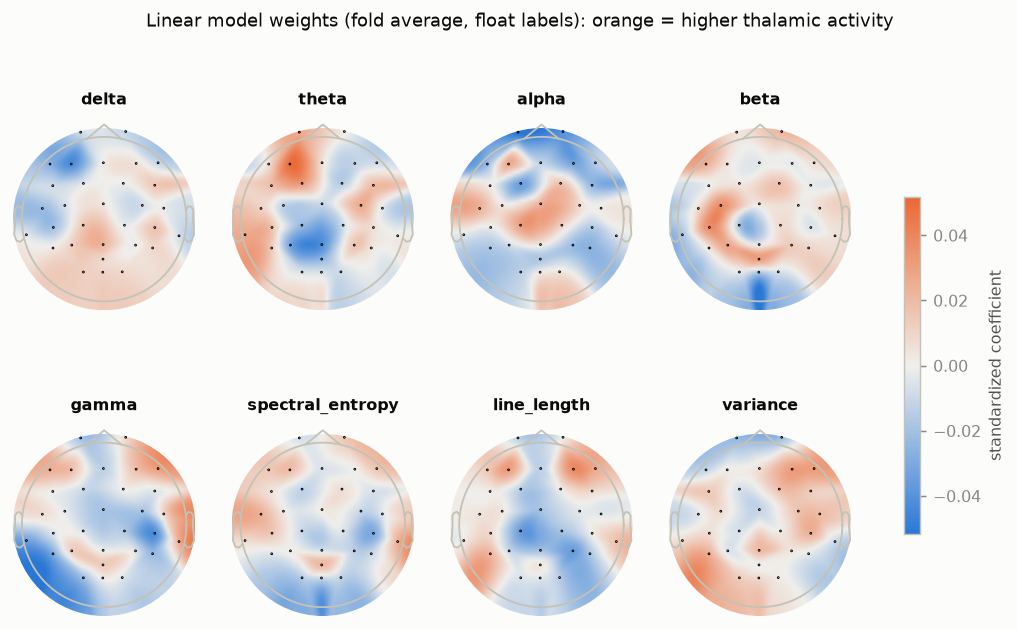

### Figures, binary labels

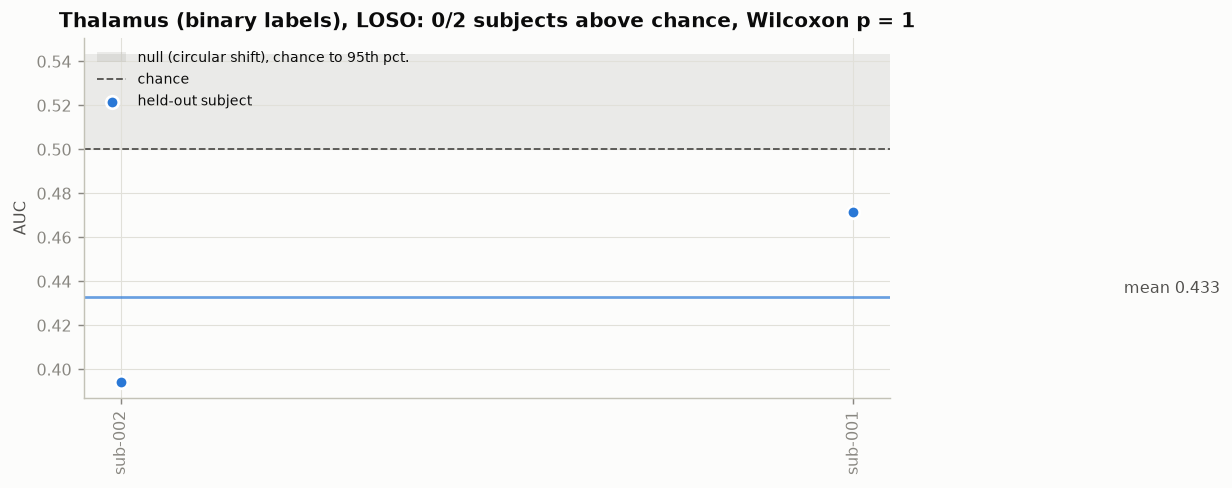

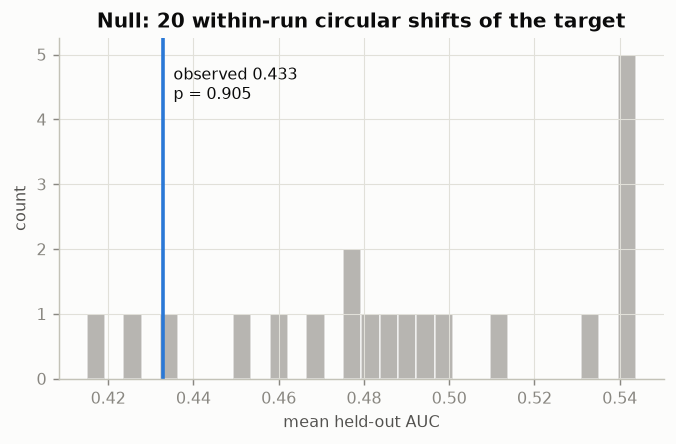

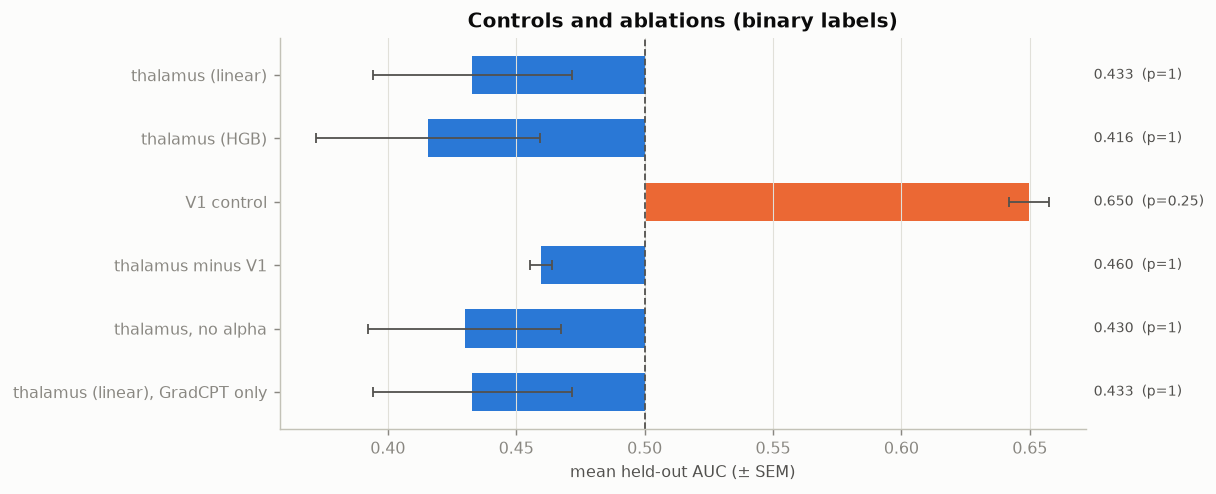

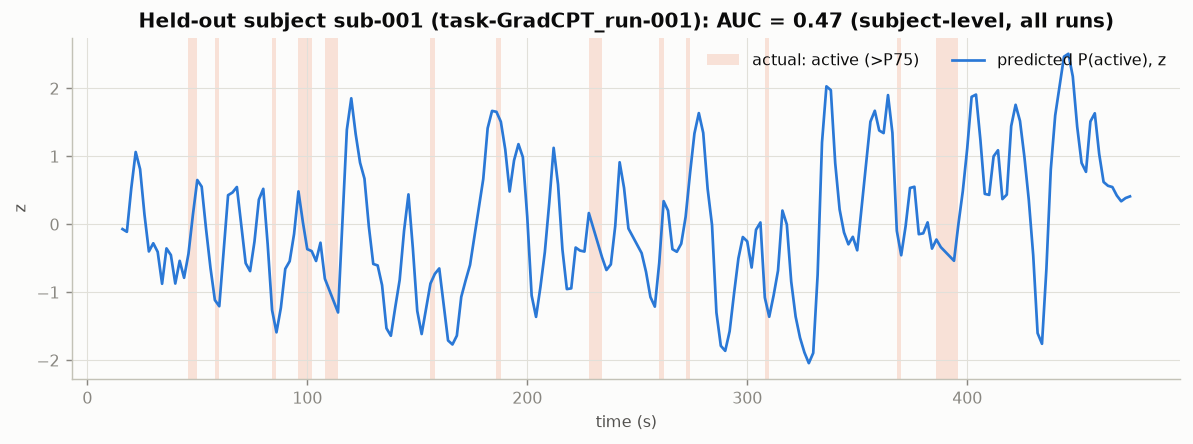

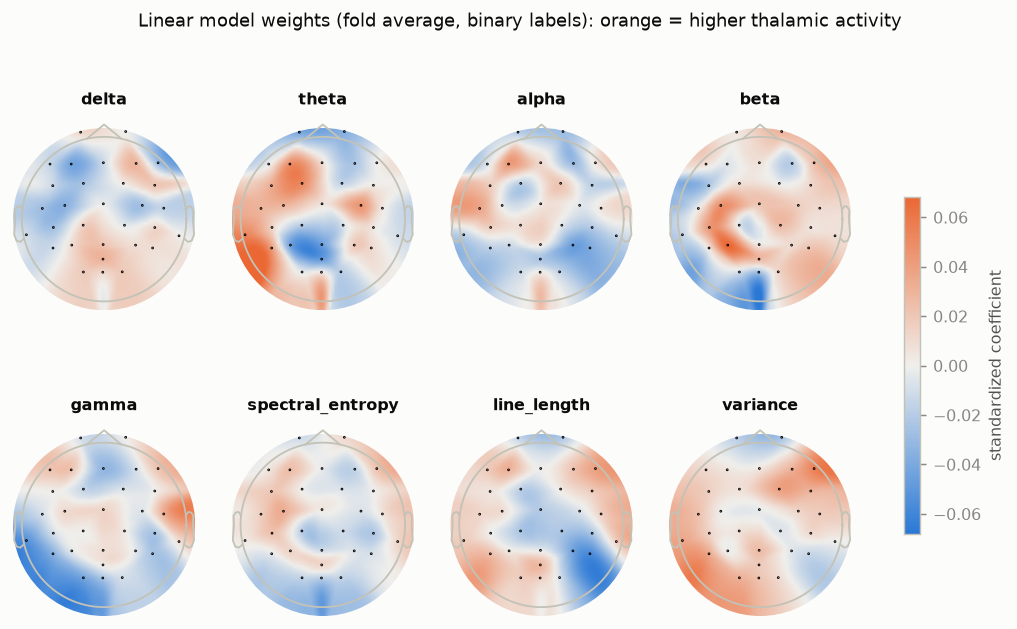

In [7]:
plots.make_all(results, paths.figures)
for mode in results:
    display(Markdown(f"### Figures, {mode} labels"))
    for name in ("subject_scores", "null", "controls", "pred_vs_actual", "topomaps"):
        f = paths.figures / f"{name}_{mode}.png"
        if f.exists(): display(Image(filename=str(f)))

## 5. How to read this, and limitations
* **EEG cannot see the thalamus directly.** At best the model learns scalp-visible correlates of thalamic BOLD: rhythms (alpha, spindle-range power), arousal and vigilance, and global state changes.
* **The V1 control is key.** If V1 is predicted about as well as the thalamus, the model is mostly tracking a generic, brain-wide signal (arousal, vigilance) rather than something thalamus-specific. The *thalamus minus V1* target estimates the thalamus-specific part directly.
* **Alpha ablation.** Alpha power tracks drowsiness. A large drop without alpha means the effect is mostly a vigilance effect.
* Subcortical BOLD has a lower SNR than cortical BOLD. The fMRI preprocessing is deliberately light: no fieldmap distortion correction, no slice timing, atlas-based masks.
* The sample is small (24 healthy young adults from one area), and gradient/BCG cleaning was done upstream by the dataset authors.

**Stretch (not implemented yet):** an attention-relevance check of thalamic BOLD at GradCPT commission errors vs correct omissions (`func/*_events.tsv`).